# 12 · Choosing an SDK or framework: one task, three builds
Level L2 · Part 2 · professional · ~30 min · builds on 05, 11

## Goal
Build one task three ways: a hand loop, a LangGraph graph with explicit nodes, and the `create_agent` helper that builds the loop for you.
Run the first two on the same question, count what each build cost, look at the steps the helper builds for you, and say which one fits which job.

## Why it matters
Three ways to build an agent are in use: write the loop, draw a graph, or call a helper. Each gives the same answer on an easy task. They
differ when the task gets harder: when you need a pause, a second agent, a saved step or a custom stop. Choosing by fashion costs a rewrite;
choosing by the job costs an hour.

| Build | Best when | Costs you |
|---|---|---|
| Hand loop | The loop is the lesson, or the task is tiny | Every stop, pause and save is your code |
| LangGraph graph | You need steps you can see, pause, save and replay | More setup than one function |
| `create_agent` | A standard tool loop with a system prompt | Less control over the steps in between |

## The idea
All three call the same model and run the same tools. The difference is who writes the loop. A hand loop is code you read top to bottom.
A graph is the same loop with its steps named and its state saved. `create_agent` is the graph with its steps fixed for you: model, tools,
and back.

## Picture
The same task, three shapes. The model's decision is amber in each. The drawing comes from `graph_view.py`, a course helper: `show_mermaid`
draws a flowchart from Mermaid text (a short text format for diagrams), and `show_graph` draws a compiled LangGraph graph with the same
colours. If the drawing service is not reachable, both print the same diagram as text.

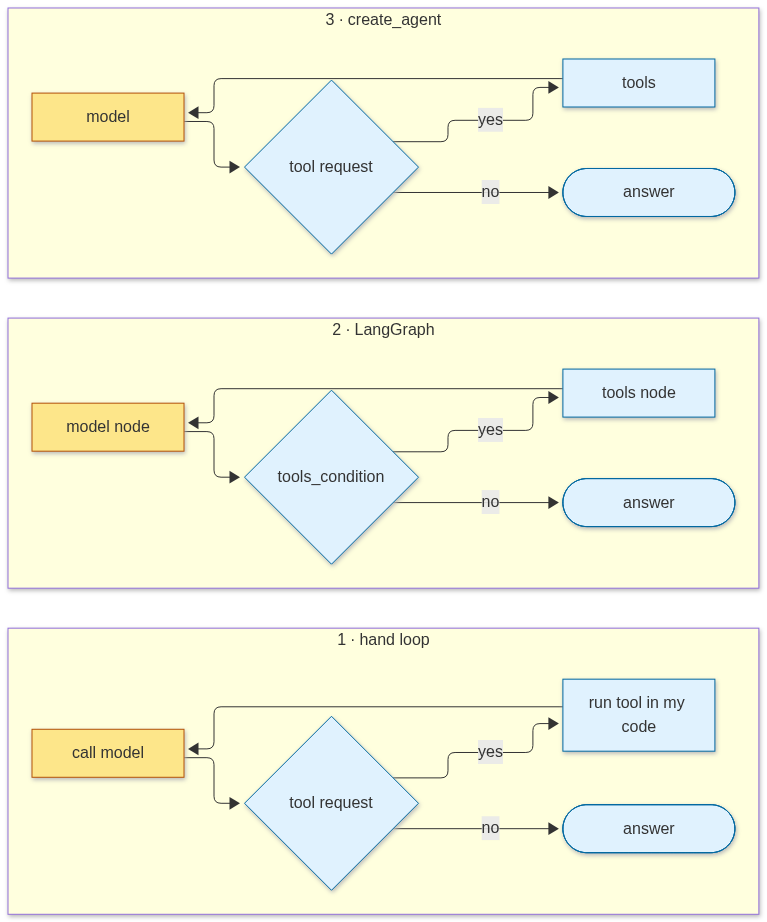

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  subgraph H["1 · hand loop"]
    h1["call model"] --> h2{"tool request"}
    h2 -->|yes| h3["run tool in my code"] --> h1
    h2 -->|no| h4(["answer"])
  end
  subgraph G["2 · LangGraph"]
    g1["model node"] --> g2{"tools_condition"}
    g2 -->|yes| g3["tools node"] --> g1
    g2 -->|no| g4(["answer"])
  end
  subgraph C["3 · create_agent"]
    c1["model"] --> c2{"tool request"}
    c2 -->|yes| c3["tools"] --> c1
    c2 -->|no| c4(["answer"])
  end
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  class h1,g1,c1 model
  class h2,h3,g2,g3,c2,c3,h4,g4,c4 code
""")

## Step by step
Each build uses the same tool and the same question, so the difference is the build and nothing else. The notebook has a limit of five
model calls, so the first two builds below are the live runs; the helper is built and drawn, not run.

**Step 1 · setup (no call).** Two helpers from the course. `llm_replay` records each model answer the first time the notebook runs and
replays it afterwards, so the lesson runs offline with no key and gives the same output every time. `get_llm()` is the course's model
setup (`llm_setup.py`): it returns the course model, on Vertex AI.

In [2]:
import sys; sys.path.insert(0, "../../..")

import json
from pathlib import Path
import llm_replay
llm_replay.start("12_choosing-a-framework")

from langchain.agents import create_agent
from langchain_core.messages import HumanMessage, ToolMessage
from langchain_core.tools import tool
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition
from pydantic import BaseModel, ConfigDict, Field
from llm_setup import get_llm
from graph_view import show_graph

llm = get_llm()
ORDERS = json.loads((Path("../../../data") / "support_eval.json").read_text())["world"]["orders"]
QUESTION = "Order 1003 never arrived. What is its status, and how late is it?"

LLM mode: replay (12_choosing-a-framework.yaml)


Gemini on Vertex AI · API key loaded: True


**Step 1 (continued) · the tool.** `lookup_order` reads one order from the lesson's support data. The argument schema says what a valid
order number looks like, so the model cannot send a malformed one. `MODEL` is the same model with the tool attached. `ask()` sends messages to `MODEL` and counts each call, so every build reports its own number.

In [3]:
class OrderQuery(BaseModel):
    model_config = ConfigDict(extra="forbid")
    order_id: str = Field(description="The order number the customer wrote: four digits, such as 1003.", pattern=r"^\d{4}$")


@tool(args_schema=OrderQuery)
def lookup_order(order_id: str) -> dict:
    """Look up one customer order: its status and days late. Use it when the customer gives an order number."""
    return ORDERS.get(order_id, {"error": f"no order {order_id}"})


MODEL = llm.bind_tools([lookup_order])
CALLS = {}  # build name -> model calls it made
N_MODEL = {"calls": 0}  # every model call this notebook makes goes through ask()


def ask(messages):
    N_MODEL["calls"] += 1
    return MODEL.invoke(messages)

**Step 2 · build 1: the hand loop (2 model calls).** You write every step. The loop is about ten lines, and it is easy to read, test and
change. Nothing is saved between steps.

In [4]:
def hand_loop(question: str) -> str:
    messages = [HumanMessage(content=question)]
    while True:
        reply = ask(messages)
        if not reply.tool_calls:
            return reply.text
        messages.append(reply)
        for c in reply.tool_calls:
            messages.append(ToolMessage(content=json.dumps(lookup_order.invoke(c["args"])), tool_call_id=c["id"]))


before = N_MODEL["calls"]
print("hand loop:", hand_loop(QUESTION))
CALLS["hand loop"] = N_MODEL["calls"] - before

hand loop: I'm very sorry to hear that. I've checked the status of order 1003, and it is currently marked as **lost**. It is **9 days late**.

I apologize for this inconvenience. Would you like me to help you initiate a refund or look into a replacement for this order?


**Step 3 · build 2: the LangGraph graph (2 model calls).** The model and the tools are named nodes, and the route is a visible edge. The
graph is more code than the loop. In return, every step can be saved, paused, streamed or replayed, as lesson 11 showed.

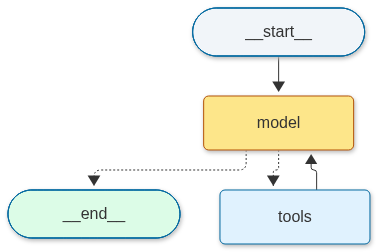

graph: I'm very sorry to hear that. I've checked the status of order 1003, and it is currently marked as **lost**. It is **9 days late**.

I apologize for this inconvenience. Would you like me to help you initiate a refund or look into a replacement for this order?


In [5]:
def call_model(state: MessagesState) -> dict:
    return {"messages": [ask(state["messages"])]}


g = StateGraph(MessagesState)
g.add_node("model", call_model)
g.add_node("tools", ToolNode([lookup_order]))
g.add_edge(START, "model")
g.add_conditional_edges("model", tools_condition, {"tools": "tools", END: END})
g.add_edge("tools", "model")
graph_app = g.compile()
show_graph(graph_app, model_nodes=("model",))
before = N_MODEL["calls"]
print("graph:", graph_app.invoke({"messages": [HumanMessage(content=QUESTION)]})["messages"][-1].text)
CALLS["graph"] = N_MODEL["calls"] - before

**Step 4 · build 3: `create_agent` (built and drawn, not run).** The helper builds the same model-and-tools loop from a model, a tool list
and a system prompt. Its build is the shortest of the three: two lines of code. The steps in between are fixed, so a custom gate or a pause needs a
graph. This cell builds it and draws it without calling the model. Running it needs at least two more model calls (a tool request and an answer),
which would take the notebook over its five-call limit.

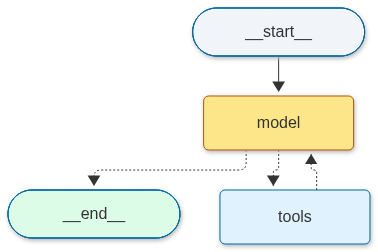

steps the helper built: ['__end__', '__start__', 'model', 'tools']


In [6]:
agent = create_agent(model=llm, tools=[lookup_order],
                     system_prompt="You are the Brightside support desk. Use the tool for order facts.")
show_graph(agent, model_nodes=("model",))
print("steps the helper built:", sorted(agent.get_graph().nodes))
llm_replay.stop()  # saves the recording: the last model call of this lesson was in step 3

## What the three builds cost
The calls are counted by each build. Both loops gave the same answer, so their difference is the code, not the model. The helper's row
is not measured in this notebook.

In [7]:
print(f"{'build':<14}{'model calls':>12}")
for name in ("hand loop", "graph"):
    print(f"{name:<14}{CALLS.get(name, 'not run'):>12}")
print(f"{'create_agent':<14}{'not run':>12}")
print("the same question, the same tool, the same model: the calls are counted by the recorder")

build          model calls
hand loop                2
graph                    2
create_agent       not run
the same question, the same tool, the same model: the calls are counted by the recorder


## Choosing
Ask three questions. Does the run need a pause, a save or a second agent? Does a step need a rule of your own? Does the team need to read
every step? If the answer to any is yes, use a graph. If the task is a standard tool loop, `create_agent` is enough. A hand loop is for
learning, or for a task so small that a framework is more to learn than the task.

## At work
- Teams start with `create_agent` for a standard loop, and move to a graph when they need a pause or a custom step. The move is local: the
  tools and the prompt stay the same → lesson 11 (why a graph).
- A hand loop in production is usually a graph in disguise: someone adds caps, saves and retries until the code is a framework.
- A framework's version can change its steps. Pin the version and test the build on upgrade → lesson 36 (serving and fleet).

## What just happened
- The hand loop made 2 model calls: one to ask for the order tool, one to answer after the tool result.
- The graph made 2 model calls for the same question, so the two loops cost the same here; the difference is the code around them.
- The helper's steps are the model node and the tools node, shown by its graph; its own call count is not measured in this notebook.

## Common mistakes
1. **Choosing by what is popular.** Choose by the job: a pause or a custom step means a graph.
2. **Assuming the helper has no steps.** `create_agent` has steps; it just does not show them. The step list printed in Step 4 shows them. Read its graph before you rely on it.
3. **Comparing the code only.** The fair comparison counts what you still have to build: caps, saves, pauses, tests.

## Try it
Write `choose(needs_pause, needs_custom_step, team_reads_steps)` that returns `"graph"` if any of the three is true, and `"create_agent"`
otherwise. Test it on `(False, False, False)` and on `(False, True, False)`. No model call is needed.

In [8]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [9]:
def choose(needs_pause: bool, needs_custom_step: bool, team_reads_steps: bool) -> str:
    return "graph" if (needs_pause or needs_custom_step or team_reads_steps) else "create_agent"


print(choose(False, False, False), choose(False, True, False))  # create_agent graph

create_agent graph


## Key terms
- **Hand loop** — the loop you write yourself around the model: call the model, run the tools it asks for, repeat until it answers.
- **Node** — one named step in a graph, such as `model` or `tools`.
- **Edge** — an arrow between nodes; a conditional edge picks the next node from the state.
- **State** — the data a graph passes from node to node and can save (here, the list of messages).
- **`tools_condition`** — the LangGraph helper that sends the run to `tools` when the model asked for a tool, and to the end when it did not.
- **`create_agent`** — the helper that builds a model-and-tools loop from a model, a tool list and a system prompt.
- **Tool call** — the model's request to run one named tool with arguments.

## Recap
- A hand loop, a graph and `create_agent` run the same loop. They differ in who names and saves the steps.
- Use a graph when you need a pause, a save, a custom step or a readable path. Use `create_agent` for a standard loop.
- Count what each build still needs you to write before you choose.

**Interview:** "Would you use a framework for this agent, and why?" Strong answer: "For a standard tool loop I would use the helper. If the
agent needs a pause for approval or a custom check, I would draw it as a graph, because the saved steps are what I need to debug and
resume it."